# Current-step squeeze pilot: bottle and sponge (14 Nov 2026)

**Protocol.** Gripper closes at cap 30 until both pads touch (`gripper: close`, target 0.6 rad past contact),
then the current cap steps 30 → 120 → 30 in steps of 10, holding 9 s at each. Flow per run:
home → `sq_lift` → `sq_<object>` → squeeze → open → `sq_lift` → home (`squeeze_<object>.yaml`).

**Objects.** Empty PET bottle, capped, squeezed near the top (marked spot). Sponge, narrow side.
Small plastic cup postponed (too wide for the gripper).

**Fingers.** TPU (compliant); pads re-mounted on 14 Nov, both the same way.

**Runs used.** bottle_02–05, sponge_01–05. Excluded: both `bottle_01` bags (movement tests).
Bench notes: sponge_01 slipped (the right pad took more of the contact).

## Research questions

| | Question | GRACE claim |
|---|---|---|
| RQ1 | Can motor signals alone (gripper position under stepped current caps) separate the two objects by compliance? | 1: motor-only estimation |
| RQ2 | What do the pads show that the motor does not? Does the pad follow the commanded current or the actual jaw force? | 2: what touch adds |
| RQ3 | How repeatable is the contact point found by `gripper: close`? | Stage 1: contact |
| RQ4 | How evenly do the two pads share the load, and at which cap does it balance? | Stage 1–2: contact geometry |
| RQ5 | Are the cap steps, hold time, top cap and `squeeze_rad` right for Experiment A? | Protocol |

In [1]:
import os, sys
from pathlib import Path
import numpy as np
sys.path.insert(0, str(Path.cwd()))
import flexigrasp_bag as fb

LOG_DIR = Path(os.environ.get("SQ_DIR", "~/flexigrasp_logs")).expanduser()
RUNS = ["bottle_02", "bottle_03", "bottle_04", "bottle_05",
        "sponge_01", "sponge_02", "sponge_03", "sponge_04", "sponge_05"]
NOTES = {"sponge_01": "slipped at the bench; right pad took more of the contact"}
bags = {lab: sorted(LOG_DIR.glob(f"*_{lab}_bag/*.db3"))[-1] for lab in RUNS}
for lab, db in bags.items():
    print(lab, db.parent.name)

bottle_02 20261114_200503_bottle_02_bag
bottle_03 20261114_200902_bottle_03_bag
bottle_04 20261114_201247_bottle_04_bag
bottle_05 20261114_201631_bottle_05_bag
sponge_01 20261114_202055_sponge_01_bag
sponge_02 20261114_202548_sponge_02_bag
sponge_03 20261114_202943_sponge_03_bag
sponge_04 20261114_203335_sponge_04_bag
sponge_05 20261114_203744_sponge_05_bag


In [2]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
BLUE, ORANGE, AQUA, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#7a5cc7"
INK, MUTED, GRID = "#1f1f1d", "#6b6b66", "#e6e6e1"
RUNCOL = [BLUE, ORANGE, AQUA, PURPLE, MUTED]
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "legend.frameon": False, "figure.dpi": 110})

## 1. Hold windows and per-hold values

Each `wait: 9` after a `cap:` step is one hold. Values are medians of the **last 3 s** of the hold:
gripper position, gripper current, and each pad's positive-taxel sum (above its value right after `rezero`).

In [3]:
def hold_windows(events):
    holds, cap, caps, t0 = [], None, [], None
    for e in events:
        if e.get("phase") != "steps":
            continue
        s = e["step"]
        if s.startswith("cap:") and e["status"] == "ok":
            cap = int(s.split(":")[1]); caps.append(cap)
        if s.startswith("wait:9"):
            if e["status"] == "start":
                t0 = e["t_bag"]
            else:
                direction = "up" if len(caps) < 2 or caps[-1] >= max(caps[:-1]) else "down"
                holds.append(dict(cap=cap, dir=direction, t0=t0, t1=e["t_bag"]))
    return holds


def analyse(db, last=3.0):
    ev = fb.read_steps(db)
    J = fb.read_joint_states(db); gi = J["names"].index("gripper")
    P = {s: fb.read_frames(db, s) for s in ("left", "right")}
    t_zero = [e["t_bag"] for e in ev if e["step"] == "rezero" and e["status"] != "start"][0]
    base = {s: np.median(P[s]["pos"][(P[s]["t"] > t_zero) & (P[s]["t"] < t_zero + 2)]) for s in P}
    close = [e for e in ev if e["step"] == "gripper:close" and e["status"] != "start"][0]
    rows = []
    for h in hold_windows(ev):
        a, b = h["t1"] - last, h["t1"]
        mj = (J["t"] >= a) & (J["t"] < b)
        ok = mj.sum() >= 5                      # joint_states may be missing (driver dropout)
        r = dict(h, gpos=np.median(J["pos"][mj, gi]) if ok else np.nan,
                 cur=np.median(J["eff"][mj, gi]) if ok else np.nan)
        for s in P:
            m = (P[s]["t"] >= a) & (P[s]["t"] < b)
            r[s] = np.median(P[s]["pos"][m]) - base[s]
            c = P[s]["cxy"][m]; good = ~np.isnan(c[:, 0])
            r[s + "_row"], r[s + "_col"] = (np.median(c[good], 0) if good.any() else (np.nan, np.nan))
        rows.append(r)
    return dict(rows=rows, contact_rad=close.get("contact_rad"), held_rad=close.get("held_rad"),
                J=J, P=P, events=ev)

res = {lab: analyse(db) for lab, db in bags.items()}
for lab, R in res.items():
    print(f"== {lab}  contact {R['contact_rad']}  held {R['held_rad']}  {NOTES.get(lab, '')}")
    for r in R["rows"]:
        print(f"  {r['dir']:4s} cap {r['cap']:3d}  gripper {r['gpos']:+.3f}  current {r['cur']:.3f} A  "
              f"L {r['left']:5.0f}  R {r['right']:5.0f}  L/R {r['left'] / max(r['right'], 1):4.2f}")

== bottle_02  contact -1.7871  held -1.692  
  up   cap  30  gripper -1.689  current 0.078 A  L   629  R   366  L/R 1.72
  up   cap  40  gripper -1.654  current 0.108 A  L   822  R   395  L/R 2.08
  up   cap  50  gripper -1.654  current 0.132 A  L   846  R   404  L/R 2.09
  up   cap  60  gripper -1.654  current 0.159 A  L   864  R   414  L/R 2.09
  up   cap  70  gripper -1.580  current 0.186 A  L  1096  R   288  L/R 3.81
  up   cap  80  gripper -1.580  current 0.215 A  L  1106  R   290  L/R 3.81
  up   cap  90  gripper -1.578  current 0.242 A  L  1107  R   301  L/R 3.68
  up   cap 100  gripper -1.506  current 0.266 A  L  1218  R  1012  L/R 1.20
  up   cap 110  gripper -1.506  current 0.293 A  L  1219  R  1039  L/R 1.17
  up   cap 120  gripper -1.506  current 0.323 A  L  1225  R  1053  L/R 1.16
  down cap 110  gripper -1.506  current 0.293 A  L  1224  R  1063  L/R 1.15
  down cap 100  gripper -1.506  current 0.266 A  L  1232  R  1065  L/R 1.16
  down cap  90  gripper -1.506  current 0.2

## 2. Data quality

- **Driver dropouts:** `/joint_states` stops for part of sponge_01 (last ~35 s) and sponge_04 (~64 s
  during unloading). Those holds have pad data but no gripper position or current, and both runs
  logged `gripper:open` timeouts. Check the arm driver's terminal output for those times.
- **sponge_01 reached the squeeze limit:** from cap 70 the gripper sits at its target (contact + 0.6 rad)
  and the current falls to ~0.08 A, so it stopped squeezing. That is the slip seen at the bench.
- **Move timeouts:** `sq_bottle` missed `move_tolerance_rad` (0.05) by 1–7 mrad, and `sq_lift`
  in teardown; harmless but each costs 15 s.

In [4]:
for lab, R in res.items():
    J = R["J"]; gap = np.diff(J["t"]).max()
    reached = [r["cap"] for r in R["rows"] if r["dir"] == "up" and r["cur"] < 0.8 * r["cap"] * 0.00269]
    print(f"{lab}: longest joint_states gap {gap:5.1f} s;  caps where current < 80% of cap: {reached}")

bottle_02: longest joint_states gap   0.3 s;  caps where current < 80% of cap: []
bottle_03: longest joint_states gap   0.3 s;  caps where current < 80% of cap: []
bottle_04: longest joint_states gap   0.3 s;  caps where current < 80% of cap: []
bottle_05: longest joint_states gap   0.3 s;  caps where current < 80% of cap: []
sponge_01: longest joint_states gap   0.2 s;  caps where current < 80% of cap: [70, 80, 90, 100, 110, 120]
sponge_02: longest joint_states gap   0.3 s;  caps where current < 80% of cap: []
sponge_03: longest joint_states gap   0.3 s;  caps where current < 80% of cap: []
sponge_04: longest joint_states gap  63.6 s;  caps where current < 80% of cap: []
sponge_05: longest joint_states gap   0.3 s;  caps where current < 80% of cap: []


## 3. RQ1: motor-only. Gripper position vs cap

Loading (solid) and unloading (dashed). Current tracks the cap exactly (0.00269 A per unit) whenever
the gripper is still pushing, so the cap is the commanded motor torque.

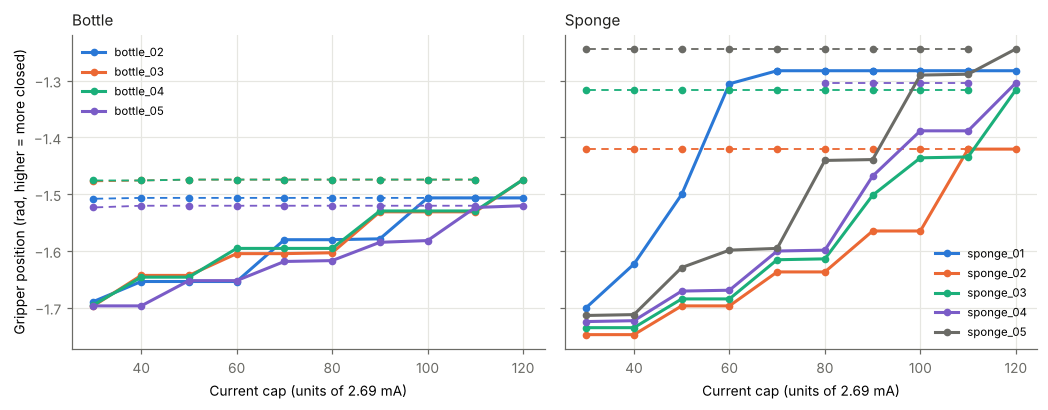

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.8), sharey=True)
for ax, obj in zip(axs, ("bottle", "sponge")):
    labs = [l for l in RUNS if l.startswith(obj)]
    for i, lab in enumerate(labs):
        rows = res[lab]["rows"]
        for d, ls in (("up", "-"), ("down", (0, (4, 3)))):
            rr = [r for r in rows if r["dir"] == d]
            ax.plot([r["cap"] for r in rr], [r["gpos"] for r in rr], color=RUNCOL[i], ls=ls,
                    lw=2 if d == "up" else 1.2, marker="o", ms=4, label=lab if d == "up" else None)
    ax.set_title(obj.capitalize(), loc="left", color=INK, fontsize=10)
    ax.set_xlabel("Current cap (units of 2.69 mA)")
    ax.legend(fontsize=7.5, loc="upper left" if obj == "bottle" else "lower right")
axs[0].set_ylabel("Gripper position (rad, higher = more closed)")
fig.tight_layout(); fig.savefig("squeeze_gripper_vs_cap.png", dpi=200)

In [6]:
print("Closing travel from cap 30 to cap 120 (loading), and a motor-only stiffness proxy")
summary = {}
for obj in ("bottle", "sponge"):
    trav, kprox = [], []
    for lab in [l for l in RUNS if l.startswith(obj)]:
        up = [r for r in res[lab]["rows"] if r["dir"] == "up"]
        d = up[-1]["gpos"] - up[0]["gpos"]
        dI = (up[-1]["cap"] - up[0]["cap"]) * 0.00269
        flag = "  (excluded: hit the squeeze limit)" if lab == "sponge_01" else ""
        print(f"  {lab}: travel {d:.3f} rad, {dI / d:.2f} A/rad{flag}")
        if lab != "sponge_01":
            trav.append(d); kprox.append(dI / d)
    summary[obj] = (np.mean(trav), np.std(trav), np.mean(kprox), np.std(kprox))
    print(f"  {obj}: travel {np.mean(trav):.3f} ± {np.std(trav):.3f} rad, "
          f"stiffness proxy {np.mean(kprox):.2f} ± {np.std(kprox):.2f} A/rad\n")

Closing travel from cap 30 to cap 120 (loading), and a motor-only stiffness proxy
  bottle_02: travel 0.183 rad, 1.33 A/rad
  bottle_03: travel 0.222 rad, 1.09 A/rad
  bottle_04: travel 0.221 rad, 1.10 A/rad
  bottle_05: travel 0.176 rad, 1.37 A/rad
  bottle: travel 0.201 ± 0.021 rad, stiffness proxy 1.22 ± 0.13 A/rad

  sponge_01: travel 0.417 rad, 0.58 A/rad  (excluded: hit the squeeze limit)
  sponge_02: travel 0.327 rad, 0.74 A/rad
  sponge_03: travel 0.419 rad, 0.58 A/rad
  sponge_04: travel 0.420 rad, 0.58 A/rad
  sponge_05: travel 0.469 rad, 0.52 A/rad
  sponge: travel 0.409 ± 0.052 rad, stiffness proxy 0.60 ± 0.08 A/rad



**What this shows**

- **The objects separate on motor signals alone.** Over the same current range the sponge closes
  about twice as far as the bottle (≈0.41 vs ≈0.21 rad), so its motor-only stiffness proxy is
  about half (≈0.6 vs ≈1.2 A/rad). Run-to-run spread is small next to that difference.
- **Stick-slip:** the jaw moves in **jumps every 2–3 cap steps**, not a smooth curve. Between jumps
  the current rises but the gripper does not move: gear static friction absorbs the extra torque
  until it is overcome.
- **No motor information on unloading:** going back down, the jaw stays where it is (friction lock),
  so the dashed lines are flat. Only the loading branch can be used for a motor-only estimate.
- **Units:** A/rad includes the TPU fingers' own give and the gear friction. It becomes N/mm after
  the load cell (current → force) and the calipers (angle → jaw mm), and the rigid-block run gives
  the fingers' share.

## 4. RQ2: what the pads add. Pad signal vs cap, and one run over time

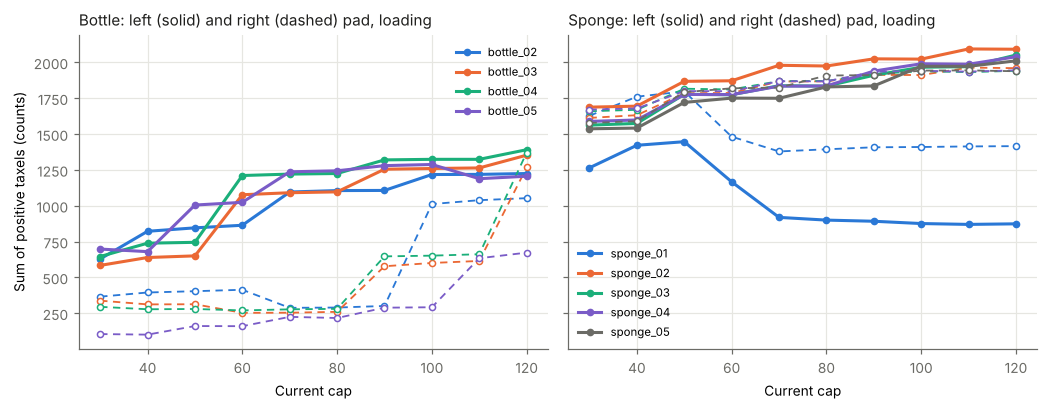

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.8), sharey=True)
for ax, obj in zip(axs, ("bottle", "sponge")):
    for i, lab in enumerate([l for l in RUNS if l.startswith(obj)]):
        up = [r for r in res[lab]["rows"] if r["dir"] == "up"]
        ax.plot([r["cap"] for r in up], [r["left"] for r in up], color=RUNCOL[i], lw=2, marker="o", ms=4, label=lab)
        ax.plot([r["cap"] for r in up], [r["right"] for r in up], color=RUNCOL[i], lw=1.2, ls=(0, (4, 3)), marker="o", ms=4, mfc="white")
    ax.set_title(f"{obj.capitalize()}: left (solid) and right (dashed) pad, loading", loc="left", color=INK, fontsize=10)
    ax.set_xlabel("Current cap"); ax.legend(fontsize=7.5)
axs[0].set_ylabel("Sum of positive taxels (counts)")
fig.tight_layout(); fig.savefig("squeeze_pads_vs_cap.png", dpi=200)

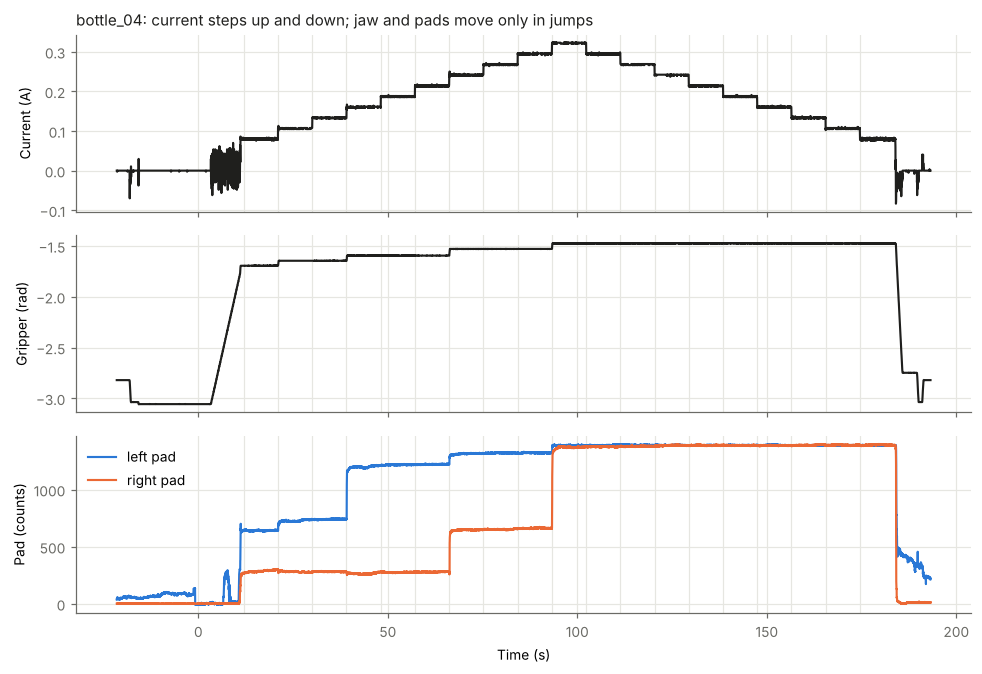

In [8]:
RUN = "bottle_04"
R = res[RUN]; J = R["J"]; gi = J["names"].index("gripper")
t0 = R["rows"][0]["t0"] - 12
fig, axs = plt.subplots(3, 1, figsize=(9, 6.2), sharex=True)
axs[0].plot(J["t"] - t0, J["eff"][:, gi], color=INK, lw=1.4); axs[0].set_ylabel("Current (A)")
axs[1].plot(J["t"] - t0, J["pos"][:, gi], color=INK, lw=1.4); axs[1].set_ylabel("Gripper (rad)")
for s, c in (("left", BLUE), ("right", ORANGE)):
    p = R["P"][s]; base = np.median(p["pos"][(p["t"] > t0) & (p["t"] < t0 + 3)])
    axs[2].plot(p["t"] - t0, p["pos"] - base, color=c, lw=1.4, label=f"{s} pad")
axs[2].set_ylabel("Pad (counts)"); axs[2].set_xlabel("Time (s)"); axs[2].legend()
for r in R["rows"]:
    for ax in axs:
        ax.axvline(r["t0"] - t0, color=GRID, lw=0.8, zorder=0)
axs[0].set_title(f"{RUN}: current steps up and down; jaw and pads move only in jumps",
                 loc="left", color=INK, fontsize=10)
fig.tight_layout(); fig.savefig(f"{RUN}_trace.png", dpi=200)

**What this shows**

- **The pads follow the jaw, not the current.** Between jumps the current rises step by step but the
  pad signal stays flat; it changes only when the jaw jumps. During unloading the current falls back
  to 0.08 A while the pads stay at their peak. So the motor current is **not** the jaw force whenever
  friction is holding the gear. The pads see the real contact. This is the clearest result so far for
  claim 2, and it means the current → force calibration (load cell) must step up **and** down.
- **Contact area differs by object:** about 105–125 active taxels on each pad for the sponge vs 23–46
  for the bottle neck. The same force gives a different count, so pad readings need area (or
  contact-taxel count) alongside the sum.
- **No pad saturation:** the highest taxel reached about 236 of 255 (bottle, right pad); most stay below 200.

## 5. RQ3: contact repeatability

In [9]:
for obj in ("bottle", "sponge"):
    labs = [l for l in RUNS if l.startswith(obj)]
    c = np.array([res[l]["contact_rad"] for l in labs]); h = np.array([res[l]["held_rad"] for l in labs])
    print(f"{obj}: contact at {c.mean():+.3f} ± {c.std():.3f} rad (range {c.max() - c.min():.3f}); "
          f"settled at cap 30: {h.mean():+.3f} ± {h.std():.3f} rad")

bottle: contact at -1.786 ± 0.003 rad (range 0.008); settled at cap 30: -1.695 ± 0.002 rad
sponge: contact at -1.843 ± 0.019 rad (range 0.058); settled at cap 30: -1.724 ± 0.016 rad


Bottle contact is very repeatable (±0.003 rad); sponge contact spreads more (±0.02 rad), as
expected for a soft surface where "contact" means a few taxels lighting up while it is still compressing.
Contact itself is already a compliance cue: the gap between first contact and the settled
position at cap 30 is ~0.09 rad for the bottle and ~0.10–0.17 rad for the sponge.

## 6. RQ4: how the two pads share the load (bench observation)

At the bench the two pads' contact signals were **level at cap ~110 for the bottle and cap ~90 for the
sponge, and unequal after that**. Below: the left/right ratio per cap, and where each run balances.

bottle_02: balances at cap 100 (L/R 3.68 -> 1.20);  jaw jumps at caps [40, 70, 100]
bottle_03: balances at cap 120 (L/R 2.06 -> 1.07);  jaw jumps at caps [40, 60, 90, 120]
bottle_04: balances at cap 120 (L/R 2.00 -> 1.01);  jaw jumps at caps [40, 60, 90, 120]
bottle_05: balances at cap None (L/R 6.65 -> 1.79);  jaw jumps at caps [50, 70, 90, 110]
sponge_01: balances at cap None (L/R 0.78 -> 0.62);  jaw jumps at caps [40, 50, 60, 70]
sponge_02: balances at cap None (L/R 1.05 -> 1.07);  jaw jumps at caps [50, 70, 90, 110]
sponge_03: balances at cap 100 (L/R 1.00 -> 1.01);  jaw jumps at caps [50, 70, 90, 100, 120]
sponge_04: balances at cap 90 (L/R 0.98 -> 1.00);  jaw jumps at caps [50, 70, 90, 100, 120]
sponge_05: balances at cap 100 (L/R 0.96 -> 1.02);  jaw jumps at caps [50, 60, 80, 100, 120]


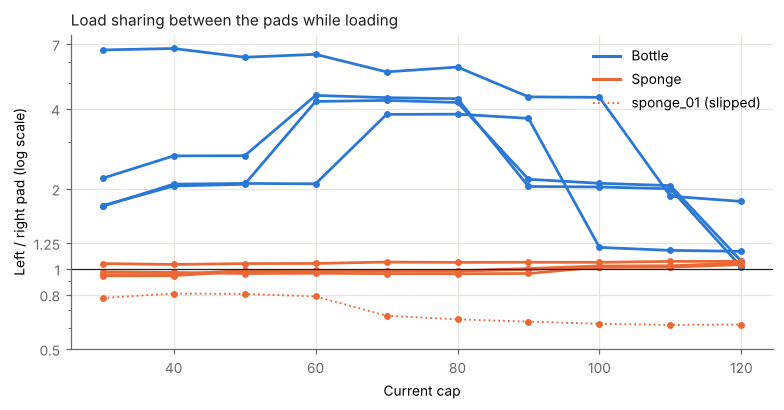

In [10]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
for obj, c in (("bottle", BLUE), ("sponge", ORANGE)):
    for lab in [l for l in RUNS if l.startswith(obj)]:
        up = [r for r in res[lab]["rows"] if r["dir"] == "up"]
        ax.plot([r["cap"] for r in up], [r["left"] / max(r["right"], 1) for r in up], color=c,
                lw=1.2 if lab == "sponge_01" else 1.8, ls=":" if lab == "sponge_01" else "-", marker="o", ms=3.5)
ax.axhline(1, color=INK, lw=0.8)
from matplotlib.ticker import NullFormatter
ax.set_yscale("log"); ax.yaxis.set_minor_formatter(NullFormatter()); ax.set_yticks([0.5, 0.8, 1, 1.25, 2, 4, 7]); ax.set_yticklabels(["0.5", "0.8", "1", "1.25", "2", "4", "7"])
ax.set_xlabel("Current cap"); ax.set_ylabel("Left / right pad (log scale)")
ax.legend(handles=[Line2D([], [], color=BLUE, lw=2, label="Bottle"), Line2D([], [], color=ORANGE, lw=2, label="Sponge"),
                   Line2D([], [], color=ORANGE, lw=1.2, ls=":", label="sponge_01 (slipped)")])
ax.set_title("Load sharing between the pads while loading", loc="left", color=INK, fontsize=10)
fig.tight_layout(); fig.savefig("squeeze_balance.png", dpi=200)

def balance_cap(rows):
    """First loading cap where left/right crosses 1 (sponge) or comes within 25% of it (bottle)."""
    up = [r for r in rows if r["dir"] == "up"]
    ratio = [r["left"] / max(r["right"], 1) for r in up]
    for i in range(1, len(up)):
        if (ratio[i - 1] - 1) * (ratio[i] - 1) <= 0 or abs(ratio[i] - 1) < 0.25 <= abs(ratio[i - 1] - 1):
            return up[i]["cap"], ratio[i - 1], ratio[i]
    return None, ratio[0], ratio[-1]

for lab in RUNS:
    rows = res[lab]["rows"]; cap, before, after = balance_cap(rows)
    jumps = [rows[i]["cap"] for i in range(1, len(rows)) if rows[i]["dir"] == "up"
             and rows[i]["gpos"] - rows[i - 1]["gpos"] > 0.02]
    print(f"{lab}: balances at cap {cap} (L/R {before:.2f} -> {after:.2f});  jaw jumps at caps {jumps}")

**What this shows**

- **Bottle:** the left pad carries 2–7× the right at low caps. The pads come level at **cap 100–120**
  (110 at the bench) in 3 of 4 runs, and each time this coincides with a **jaw jump**, while the right
  pad's contact centre moves 3–5 taxels to line up with the left. The bottle was first pressed on
  the right pad's edge, and it re-seats squarely once a jump pushes it. After that the ratio stays
  near 1.0–1.2, even while unloading (the jaw is locked).
- **Sponge:** the pads are close throughout (ratio 0.95–1.07) but **cross over at cap 90–100**:
  the right pad leads below it, the left above. The contact centres drift steadily across both pads
  as the sponge bulges.
- **So the balance cap is real, and it differs by object**, as noticed at the bench. Two explanations
  are possible: the object (a rigid object needs more force to re-seat than a soft one) or placement
  (how far off-centre it started). Experiment A should separate them: note or photograph the placement
  in every run, and compare runs with the same placement.
- For GRACE this is useful in its own right: an uneven pad ratio flags a poorly seated grasp,
  something the motor cannot see.

## 7. RQ5: protocol for Experiment A

- **Close direction:** `close_sign: 1.0` must be in every sequence file (bottle_01 failed without it).
- **`squeeze_rad`:** 0.6 rad was reached by sponge_01 and nearly by sponge_05 (the current fell short
  of the cap at 120). Use **0.9** for soft objects.
- **Cap steps:** stick-slip moves the jaw only every 2–3 steps of 10. Either keep steps of 10 and fit
  the loading staircase, or use **steps of 20** to halve run time (each step then usually gives one jump).
- **Unloading:** gives no motor information (the jaw is friction-locked), and the pads simply hold.
  A short unload (one or two steps) is enough to show the lock; skip the full staircase down.
- **Hold time:** the gripper settles within ~1 s of a jump and the pads drift < 5 counts/s afterwards:
  **5 s holds** would do.
- **Top cap 120** was safe for both; the bottle did not visibly deform at the neck.
- **Driver dropouts** (sponge_01, sponge_04) need looking into before the 40-run set.
- **Residual after release:** the left pad sat 350–450 counts above zero 2 s after the bottle runs
  opened (sponge runs 50–230). Check whether the bottle leans on the left finger after release, or
  whether the left mount now lags.

## 8. Summary

| | Bottle (neck) | Sponge (narrow side) |
|---|---|---|
| Closing travel, cap 30 → 120 | ≈0.21 rad | ≈0.41 rad |
| Motor-only stiffness proxy | ≈1.2 A/rad | ≈0.6 A/rad |
| Contact point spread | ±0.003 rad | ±0.02 rad |
| Active taxels per pad at cap 120 | 23–46 | 105–125 |
| Pads level at | cap 100–120 (bench: 110) | cap 90–100 (bench: 90) |

**Answers.** RQ1: yes, the two objects separate on motor signals alone, using the loading branch.
RQ2: the pads track the jaw, while the current does not under friction; they also show contact area
and seating. RQ3: contact is repeatable to a few mrad on rigid objects. RQ4: the load balances at an
object-dependent cap that coincides with a jaw jump. RQ5: changes listed above.